#Anomaly Detector

##Exploratory Data Analysis

###Import Libraries

In [ ]:
# Install PyTorch (if not already installed)
!pip install torch torchvision torchaudio

# Install PyOD (Python Outlier Detection library)
!pip install pyod

# Install Plotly (usually available but just in case)
!pip install plotly

# Install scikit-learn (usually pre-installed but for completeness)
!pip install scikit-learn

# Install TensorFlow (usually pre-installed but for completeness)
!pip install tensorflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.3/46.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.6/200.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.9/319.9 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 113.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 115.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 118.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.2 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.31.1
    Uninstalling protobuf-6.31.1:
      Success

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

# Feature Engineering Step #2
from scipy import stats
from scipy.stats import normaltest

###Load the Dataset and Preview

In [ ]:
#Connect to the Google Drive
from google.colab import drive
# drive.mount('/content/drive')

# Load the dataset
df = pd.read_csv('anomaly_detection_dataset.csv')

# Drop all rows with any null values
df = df.dropna()

print("Dataset Overview:")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print("\nFirst few rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
print(df.describe())

Dataset Overview:
Shape: (773805, 12)
Columns: ['fwd_header_size_min', 'down_up_ratio', 'bwd_last_window_size', 'fwd_header_size_tot', 'fwd_last_window_size', 'fwd_PSH_flag_count', 'flow_duration', 'payload_bytes_per_second', 'flow_RST_flag_count', 'fwd_data_pkts_tot', 'bwd_pkts_tot', 'fwd_pkts_per_sec']

First few rows:
   fwd_header_size_min  down_up_ratio  bwd_last_window_size  \
0             -0.80081            0.0                   0.0   
1             -0.80081            0.0                   0.0   
2             -0.80081            0.0                   0.0   
3             -0.80081            0.0                   0.0   
4             -0.80081            0.0                   0.0   

   fwd_header_size_tot  fwd_last_window_size  fwd_PSH_flag_count  \
0             0.019231                   0.0                 0.0   
1             0.019231                   0.0                 0.0   
2             0.019231                   0.0                 0.0   
3             0.019231    

### Testing the Correlation Matrix

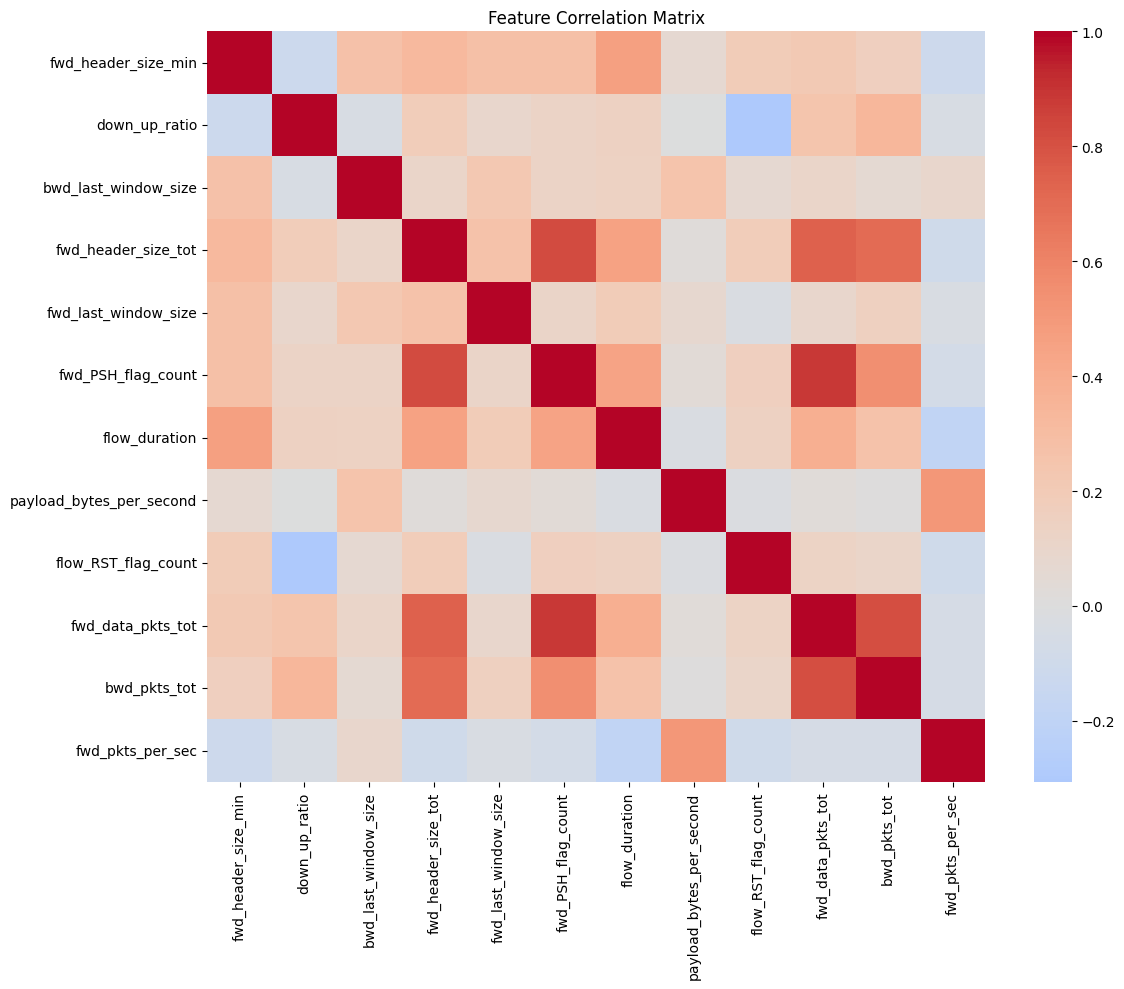

In [ ]:
# Correlation matrix
plt.figure(figsize=(12, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

### Dividing Training and Testing Data

In [ ]:
# =============================================================================
# DATA PREPARATION (Using Pre-processed Dataset)
# =============================================================================
from sklearn.model_selection import train_test_split

# Since features are already selected and scaled in your previous notebook
# we can directly use the engineered dataset
print("Using pre-processed and scaled dataset from feature engineering...")
print(f"Dataset shape: {df.shape}")
print(f"All features are already selected and scaled")

# Use all columns as they are already optimally selected and scaled
X = df.copy()
feature_columns = list(df.columns)

print(f"Selected features: {len(feature_columns)}")
print(f"Feature names: {feature_columns[:10]}{'...' if len(feature_columns) > 10 else ''}")

# Split data for training and testing (since all data is normal/benign)
X_train, X_test = train_test_split(X.values, test_size=0.3, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Using pre-processed and scaled dataset from feature engineering...
Dataset shape: (773805, 12)
All features are already selected and scaled
Selected features: 12
Feature names: ['fwd_header_size_min', 'down_up_ratio', 'bwd_last_window_size', 'fwd_header_size_tot', 'fwd_last_window_size', 'fwd_PSH_flag_count', 'flow_duration', 'payload_bytes_per_second', 'flow_RST_flag_count', 'fwd_data_pkts_tot']...
Training set shape: (541663, 12)
Test set shape: (232142, 12)


# Model Training

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
class EnhancedAnomalyDetectionModels:
    def __init__(self):
        self.models = {}
        self.results = {}
        self.training_times = {}
        self.prediction_times = {}
        # Enhanced attributes
        self.best_params = {}
        self.scalers = {}
        self.model_info = {}

    def _grid_search_ocsvm(self, X_train, X_val, y_val, param_grid):
        """Custom grid search for One-Class SVM"""
        best_score = -np.inf
        best_model = None
        best_params = None

        param_combinations = list(ParameterGrid(param_grid))
        print(f"Testing {len(param_combinations)} parameter combinations...")

        for i, params in enumerate(param_combinations):
            try:
                # Skip incompatible parameter combinations
                if params['kernel'] != 'poly' and 'degree' in params:
                    continue
                if params['kernel'] not in ['poly', 'sigmoid'] and 'coef0' in params:
                    continue

                model = OneClassSVM(**params)
                model.fit(X_train)

                y_pred = model.predict(X_val)
                score = self._calculate_anomaly_score(y_val, y_pred)

                if score > best_score:
                    best_score = score
                    best_model = model
                    best_params = params

            except Exception as e:
                continue

            if (i + 1) % 20 == 0:
                print(f"Tested {i + 1}/{len(param_combinations)} combinations")

        print(f"Best score: {best_score:.4f}")
        return best_model, best_params

    def _calculate_anomaly_score(self, y_true, y_pred):
        """Calculate F1-score for anomaly detection"""
        y_pred_binary = (y_pred == 1).astype(int)

        tp = np.sum((y_true == 0) & (y_pred_binary == 0))
        fp = np.sum((y_true == 1) & (y_pred_binary == 0))
        fn = np.sum((y_true == 0) & (y_pred_binary == 1))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

        return f1_score

    def predict_anomalies(self, X_test, model_name):
        """Enhanced prediction method that handles scaling"""
        if model_name not in self.models:
            raise ValueError(f"Model {model_name} not found")

        start_time = time.time()
        model = self.models[model_name]

        # Apply scaling if available
        if model_name in self.scalers:
            X_test_processed = self.scalers[model_name].transform(X_test)
        else:
            X_test_processed = X_test

        # Get predictions based on model type
        if model_name == 'Autoencoder':
            reconstructed = model.predict(X_test_processed)
            mse = np.mean(np.power(X_test_processed - reconstructed, 2), axis=1)
            # Use adaptive threshold based on training data reconstruction error
            threshold = self.model_info.get('Autoencoder', {}).get('threshold', np.percentile(mse, 90))
            predictions = (mse > threshold).astype(int)
        else:
            predictions = model.predict(X_test_processed)
            # Convert sklearn anomaly predictions (-1 for anomaly, 1 for normal) to (1 for anomaly, 0 for normal)
            if np.unique(predictions).tolist() == [-1, 1]:
                predictions = (predictions == -1).astype(int)

        prediction_time = time.time() - start_time
        if model_name not in self.prediction_times:
            self.prediction_times[model_name] = []
        self.prediction_times[model_name].append(prediction_time)

        return predictions

    def get_decision_scores(self, X_test, model_name):
        """Get decision scores for interpretability"""
        if model_name not in self.models:
            raise ValueError(f"Model {model_name} not found")

        model = self.models[model_name]

        # Apply scaling if available
        if model_name in self.scalers:
            X_test_processed = self.scalers[model_name].transform(X_test)
        else:
            X_test_processed = X_test

        # Get decision scores based on model type
        if hasattr(model, 'decision_function'):
            return model.decision_function(X_test_processed)
        elif hasattr(model, 'score_samples'):
            return model.score_samples(X_test_processed)
        elif model_name == 'Autoencoder':
            reconstructed = model.predict(X_test_processed)
            return -np.mean(np.power(X_test_processed - reconstructed, 2), axis=1)
        else:
            return None

    # Add this method to the EnhancedAnomalyDetectionModels class
    def predict_anomalies_improved(self, X_test, model_name):
        """Enhanced prediction method with better preprocessing"""
        if model_name not in self.models:
            raise ValueError(f"Model {model_name} not found")

        start_time = time.time()
        model = self.models[model_name]

        # Apply scaling
        if model_name in self.scalers:
            X_test_processed = self.scalers[model_name].transform(X_test)
        else:
            X_test_processed = X_test

        # Apply PCA if available
        if f'{model_name}_PCA' in self.scalers:
            X_test_processed = self.scalers[f'{model_name}_PCA'].transform(X_test_processed)

        # Get predictions (same as original method)
        if model_name == 'Autoencoder':
            reconstructed = model.predict(X_test_processed)
            mse = np.mean(np.power(X_test_processed - reconstructed, 2), axis=1)
            threshold = self.model_info.get('Autoencoder', {}).get('threshold', np.percentile(mse, 90))
            predictions = (mse > threshold).astype(int)
        else:
            predictions = model.predict(X_test_processed)
            if np.unique(predictions).tolist() == [-1, 1]:
                predictions = (predictions == -1).astype(int)

        prediction_time = time.time() - start_time
        if model_name not in self.prediction_times:
            self.prediction_times[model_name] = []
        self.prediction_times[model_name].append(prediction_time)

        return predictions

In [ ]:
class OneClassSVMEnsemble:
    """Ensemble wrapper for One-Class SVM models"""

    def __init__(self, models):
        self.models = models
        self.n_models = len(models)

    def predict(self, X):
        """Ensemble prediction using majority voting"""
        predictions = np.array([model.predict(X) for model in self.models])
        # Convert to binary (1 for normal, 0 for anomaly)
        predictions_binary = (predictions == 1).astype(int)
        # Majority vote
        ensemble_pred = (np.mean(predictions_binary, axis=0) >= 0.5).astype(int)
        # Convert back to One-Class SVM format (-1 for anomaly, 1 for normal)
        return np.where(ensemble_pred == 1, 1, -1)

    def decision_function(self, X):
        """Ensemble decision function using average scores"""
        scores = np.array([model.decision_function(X) for model in self.models])
        return np.mean(scores, axis=0)

In [ ]:
class IsolationForestEnsemble:
    """Ensemble wrapper for Isolation Forest models"""

    def __init__(self, models):
        self.models = models
        self.n_models = len(models)

    def predict(self, X):
        """Ensemble prediction using majority voting"""
        predictions = np.array([model.predict(X) for model in self.models])
        # Convert to binary (1 for normal, 0 for anomaly)
        predictions_binary = (predictions == 1).astype(int)
        # Majority vote
        ensemble_pred = (np.mean(predictions_binary, axis=0) >= 0.5).astype(int)
        # Convert back to sklearn format (-1 for anomaly, 1 for normal)
        return np.where(ensemble_pred == 1, 1, -1)

    def decision_function(self, X):
        """Ensemble decision function using average scores"""
        scores = np.array([model.decision_function(X) for model in self.models])
        return np.mean(scores, axis=0)

    def score_samples(self, X):
        """Ensemble score samples using average scores"""
        scores = np.array([model.score_samples(X) for model in self.models])
        return np.mean(scores, axis=0)

In [ ]:
def train_enhanced_one_class_svm(model_class, X_train, kernel='rbf', nu=0.082, gamma='scale',
                                        optimize_params=False, X_val=None, y_val=None, custom_params=None,
                                        use_robust_scaling=True, apply_pca=False, pca_variance=0.95,
                                        use_ensemble=False, n_estimators=5):
    """
    Improved One-Class SVM Implementation with Enhanced Features

    Parameters:
    -----------
    model_class : EnhancedAnomalyDetectionModels instance
    X_train : array-like, training data (benign only)
    kernel : str, kernel type
    nu : float, expected fraction of outliers (FIXED at 0.082)
    gamma : str or float, kernel coefficient
    optimize_params : bool, whether to perform parameter optimization
    X_val : array-like, validation data (optional)
    y_val : array-like, validation labels (optional)
    custom_params : dict, custom parameter ranges
    use_robust_scaling : bool, use RobustScaler instead of StandardScaler
    apply_pca : bool, apply PCA for dimensionality reduction
    pca_variance : float, variance to retain in PCA
    use_ensemble : bool, use ensemble of One-Class SVMs
    n_estimators : int, number of estimators for ensemble
    """
    print("="*60)
    print("TRAINING IMPROVED ONE-CLASS SVM")
    print("="*60)
    print(f"Using FIXED nu parameter: {nu}")

    start_time = time.time()

    # IMPROVEMENT 1: Enhanced Scaling Options
    if use_robust_scaling:
        from sklearn.preprocessing import RobustScaler
        scaler = RobustScaler()  # Less sensitive to outliers than StandardScaler
        print("Using RobustScaler for better outlier handling...")
    else:
        scaler = StandardScaler()
        print("Using StandardScaler...")

    X_train_scaled = scaler.fit_transform(X_train)
    model_class.scalers['OneClassSVM'] = scaler

    # IMPROVEMENT 2: Optional PCA for Dimensionality Reduction
    if apply_pca:
        from sklearn.decomposition import PCA
        pca = PCA(n_components=pca_variance, random_state=42)
        X_train_scaled = pca.fit_transform(X_train_scaled)
        model_class.scalers['OneClassSVM_PCA'] = pca
        print(f"Applied PCA: {X_train_scaled.shape[1]} components retaining {pca_variance*100}% variance")

    if optimize_params and X_val is not None and y_val is not None:
        print("Optimizing One-Class SVM parameters (nu FIXED at 0.082)...")

        # Scale validation data
        X_val_scaled = scaler.transform(X_val)
        if apply_pca:
            X_val_scaled = pca.transform(X_val_scaled)

        # IMPROVEMENT 3: Enhanced Parameter Grid (nu fixed)
        if custom_params is None:
            param_grid = {
                'kernel': ['rbf', 'linear', 'poly', 'sigmoid'],
                'nu': [nu],  # FIXED VALUE
                'gamma': ['scale', 'auto', 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
                'shrinking': [True, False],
                'tol': [1e-4, 1e-3, 1e-2],
                'coef0': [0.0, 0.1, 1.0],  # For poly and sigmoid kernels
                'degree': [2, 3, 4]  # For poly kernel
            }
        else:
            custom_params['nu'] = [nu]  # Ensure nu is fixed
            param_grid = custom_params

        best_model, best_params = model_class._grid_search_ocsvm(
            X_train_scaled, X_val_scaled, y_val, param_grid
        )

        model_class.best_params['OneClassSVM'] = best_params
        print(f"Best parameters: {best_params}")
        model = best_model

    else:
        # IMPROVEMENT 4: Ensemble of One-Class SVMs
        if use_ensemble:
            print(f"Training ensemble of {n_estimators} One-Class SVMs...")
            ensemble_models = []

            # Different configurations for ensemble diversity
            ensemble_configs = [
                {'kernel': 'rbf', 'gamma': 'scale'},
                {'kernel': 'rbf', 'gamma': 'auto'},
                {'kernel': 'linear'},
                {'kernel': 'poly', 'degree': 3, 'coef0': 0.1},
                {'kernel': 'sigmoid', 'coef0': 0.1}
            ]

            for i in range(n_estimators):
                config = ensemble_configs[i % len(ensemble_configs)]
                model_i = OneClassSVM(
                    nu=nu,
                    shrinking=True,
                    tol=1e-3,
                    cache_size=500,
                    **config
                )
                model_i.fit(X_train_scaled)
                ensemble_models.append(model_i)

            # Create ensemble wrapper
            model = OneClassSVMEnsemble(ensemble_models)
            print(f"Ensemble trained with {len(ensemble_models)} models")

        else:
            # IMPROVEMENT 5: Enhanced single model with better parameters
            if kernel == 'rbf':
                gamma = 1.0 / (X_train_scaled.shape[1] * X_train_scaled.var())  # Adaptive gamma

            model = OneClassSVM(
                kernel=kernel,
                nu=nu,
                gamma=gamma,
                shrinking=True,
                tol=1e-4,  # Tighter tolerance
                cache_size=1000,  # Larger cache
                max_iter=10000  # More iterations if needed
            )
            model.fit(X_train_scaled)

    training_time = time.time() - start_time
    model_class.models['OneClassSVM'] = model
    model_class.training_times['OneClassSVM'] = training_time

    print(f"Improved One-Class SVM training completed in {training_time:.2f} seconds")
    print(f"Model uses {kernel} kernel with FIXED nu={nu}")

    return model

In [ ]:
def train_isolation_forest(model_class, X_train, contamination=0.082, n_estimators=200,
                                   max_samples='auto', max_features=1.0, use_ensemble=False,
                                   bootstrap=True, warm_start=False):
    """
    Improved Isolation Forest Implementation

    Parameters:
    -----------
    model_class : EnhancedAnomalyDetectionModels instance
    X_train : array-like, training data (benign only)
    contamination : float, expected proportion of outliers (fixed at 0.082)
    n_estimators : int, number of base estimators (increased to 200)
    max_samples : int or str, number of samples to draw
    max_features : int or float, number of features to draw
    use_ensemble : bool, use ensemble of multiple IF models
    bootstrap : bool, whether to use bootstrap sampling
    warm_start : bool, whether to reuse previous solution
    """
    print("="*60)
    print("TRAINING IMPROVED ISOLATION FOREST")
    print("="*60)
    print(f"Using contamination parameter: {contamination}")

    start_time = time.time()

    if use_ensemble:
        print("Training ensemble of Isolation Forest models...")
        ensemble_models = []

        # Different configurations for ensemble diversity
        ensemble_configs = [
            {'max_samples': 'auto', 'max_features': 1.0, 'bootstrap': True},
            {'max_samples': 256, 'max_features': 0.8, 'bootstrap': True},
            {'max_samples': 512, 'max_features': 0.9, 'bootstrap': False},
            {'max_samples': 'auto', 'max_features': 0.7, 'bootstrap': True},
            {'max_samples': 128, 'max_features': 1.0, 'bootstrap': False}
        ]

        for i, config in enumerate(ensemble_configs):
            model_i = IsolationForest(
                contamination=contamination,
                n_estimators=n_estimators // len(ensemble_configs),  # Distribute estimators
                random_state=42 + i,
                n_jobs=-1,
                **config
            )
            model_i.fit(X_train)
            ensemble_models.append(model_i)

        # Create ensemble wrapper
        model = IsolationForestEnsemble(ensemble_models)
        print(f"Ensemble trained with {len(ensemble_models)} models")

    else:
        # Enhanced single model with better parameters
        # Adaptive max_samples based on dataset size
        if max_samples == 'auto':
            n_samples = X_train.shape[0]
            if n_samples > 10000:
                max_samples = min(2048, n_samples // 4)  # Use subset for large datasets
            else:
                max_samples = min(256, n_samples)

        model = IsolationForest(
            contamination=contamination,
            n_estimators=n_estimators,
            max_samples=max_samples,
            max_features=max_features,
            bootstrap=bootstrap,
            random_state=42,
            n_jobs=-1,
            warm_start=warm_start,
            verbose=0
        )
        model.fit(X_train)

    training_time = time.time() - start_time
    model_class.models['IsolationForest'] = model
    model_class.training_times['IsolationForest'] = training_time

    print(f"Improved Isolation Forest training completed in {training_time:.2f} seconds")
    print(f"Model parameters: contamination={contamination}, n_estimators={n_estimators}")

    return model

In [ ]:
def train_local_outlier_factor(model_class, X_train, n_neighbors=20, contamination=0.1,
                              algorithm='auto', leaf_size=30):
    """
    Enhanced Local Outlier Factor Implementation

    Parameters:
    -----------
    model_class : EnhancedAnomalyDetectionModels instance
    X_train : array-like, training data (benign only)
    n_neighbors : int, number of neighbors
    contamination : float, expected proportion of outliers
    algorithm : str, algorithm for nearest neighbors
    leaf_size : int, leaf size for tree algorithms
    """
    print("="*60)
    print("TRAINING LOCAL OUTLIER FACTOR")
    print("="*60)

    start_time = time.time()

    model = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination,
        novelty=True,
        algorithm=algorithm,
        leaf_size=leaf_size,
        n_jobs=-1
    )
    model.fit(X_train)

    training_time = time.time() - start_time
    model_class.models['LOF'] = model
    model_class.training_times['LOF'] = training_time

    print(f"LOF training completed in {training_time:.2f} seconds")
    print(f"Model parameters: n_neighbors={n_neighbors}, contamination={contamination}")

    return model

In [ ]:
def train_autoencoder(model_class, X_train, encoding_dim_ratio=0.25, epochs=50,
                     batch_size=32, validation_split=0.1, learning_rate=0.001):
    """
    Enhanced Autoencoder Implementation

    Parameters:
    -----------
    model_class : EnhancedAnomalyDetectionModels instance
    X_train : array-like, training data (benign only)
    encoding_dim_ratio : float, ratio of encoding dimension to input dimension
    epochs : int, number of training epochs
    batch_size : int, batch size for training
    validation_split : float, validation split ratio
    learning_rate : float, learning rate for optimizer
    """
    print("="*60)
    print("TRAINING AUTOENCODER")
    print("="*60)

    # Clear any existing sessions
    tf.keras.backend.clear_session()

    # Force CPU usage for stability (remove if you want GPU)
    with tf.device('/cpu:0'):
        start_time = time.time()

        # Build model
        input_dim = X_train.shape[1]
        encoding_dim = max(2, int(input_dim * encoding_dim_ratio))

        autoencoder = keras.Sequential([
            layers.Dense(encoding_dim * 2, activation='relu', input_shape=(input_dim,)),
            layers.Dropout(0.1),
            layers.Dense(encoding_dim, activation='relu'),
            layers.Dropout(0.1),
            layers.Dense(encoding_dim * 2, activation='relu'),
            layers.Dense(input_dim, activation='linear')
        ])

        # Use custom learning rate
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
        autoencoder.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

        # Train model
        history = autoencoder.fit(
            X_train, X_train,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=validation_split,
            verbose=1,
            shuffle=True
        )

        # Calculate threshold for anomaly detection
        reconstructed = autoencoder.predict(X_train)
        mse = np.mean(np.power(X_train - reconstructed, 2), axis=1)
        threshold = np.percentile(mse, 95)  # Top 5% as anomalies

        end_time = time.time()
        training_time = end_time - start_time

        model_class.models['Autoencoder'] = autoencoder
        model_class.training_times['Autoencoder'] = training_time
        model_class.model_info['Autoencoder'] = {'threshold': threshold, 'history': history}

        print(f"Autoencoder training completed in {training_time:.2f} seconds")
        print(f"Encoding dimension: {encoding_dim}, Threshold: {threshold:.4f}")

        return autoencoder, history

In [ ]:
def evaluate_pure_benign_data(model_class, X_test):
    """
    Proper evaluation for pure benign data scenario

    Since all test data is benign:
    - ANY anomaly prediction = False Positive
    - Goal: Minimize false positive rate
    """
    print("="*60)
    print("CORRECTED EVALUATION - PURE BENIGN DATA")
    print("="*60)

    # Ground truth: ALL samples are normal (benign)
    y_true = np.zeros(len(X_test), dtype=int)  # All samples are normal

    results = {}

    for model_name in model_class.models.keys():
        print(f"\nEvaluating {model_name}...")

        # Get predictions
        predictions = model_class.predict_anomalies_improved(X_test, model_name)

        # Calculate metrics
        n_predicted_anomalies = np.sum(predictions)
        false_positive_rate = (n_predicted_anomalies / len(X_test)) * 100
        accuracy = accuracy_score(y_true, predictions)

        results[model_name] = {
            'predicted_anomalies': n_predicted_anomalies,
            'false_positive_rate_%': false_positive_rate,
            'accuracy': accuracy
        }

        print(f"  Predicted anomalies: {n_predicted_anomalies} ({false_positive_rate:.2f}%)")
        print(f"  Accuracy: {accuracy:.4f}")

        # Performance assessment
        if false_positive_rate <= 5:
            print(f"  ✅ GOOD: Low false positive rate")
        else:
            print(f"  ❌ HIGH: Too many false positives")

    return results

In [ ]:
def fix_model_parameters(model_class, X_train):
    """
    Retrain models with corrected parameters to reduce false positives
    """
    print("Retraining models with corrected parameters...")

    # Clear previous models
    model_class.models.clear()
    model_class.training_times.clear()
    model_class.scalers.clear()

    # Retrain with lower contamination/nu parameters
    train_enhanced_one_class_svm(model_class, X_train, nu=0.05, use_robust_scaling=False)
    train_isolation_forest(model_class, X_train, contamination=0.05)
    train_local_outlier_factor(model_class, X_train, contamination=0.05)

    # Retrain autoencoder with stricter threshold
    autoencoder, history = train_autoencoder(model_class, X_train)
    reconstructed = autoencoder.predict(X_train)
    mse = np.mean(np.power(X_train - reconstructed, 2), axis=1)
    stricter_threshold = np.percentile(mse, 98)  # 98th percentile instead of 95th
    model_class.model_info['Autoencoder']['threshold'] = stricter_threshold

    print("✅ Models retrained with corrected parameters")


def tune_ocsvm_threshold(model_class, X_train, model_name='OneClassSVM', target_fpr=0.05):
    """
    Tune the decision threshold to achieve target false positive rate
    """
    print(f"Tuning threshold for {model_name} to achieve {target_fpr*100}% FPR...")

    model = model_class.models[model_name]

    # Apply same preprocessing as training
    if model_name in model_class.scalers:
        X_train_processed = model_class.scalers[model_name].transform(X_train)
    else:
        X_train_processed = X_train

    if f'{model_name}_PCA' in model_class.scalers:
        X_train_processed = model_class.scalers[f'{model_name}_PCA'].transform(X_train_processed)

    # Get decision scores
    scores = model.decision_function(X_train_processed)

    # Find threshold that gives target FPR
    threshold = np.percentile(scores, target_fpr * 100)

    # Store threshold
    if 'thresholds' not in model_class.model_info:
        model_class.model_info['thresholds'] = {}
    model_class.model_info['thresholds'][model_name] = threshold

    print(f"Optimal threshold: {threshold:.4f}")
    return threshold


def tune_isolation_forest_threshold(model_class, X_train, model_name='IsolationForest', target_fpr=0.05):
    """
    Tune the decision threshold for Isolation Forest to achieve target false positive rate
    """
    print(f"Tuning threshold for {model_name} to achieve {target_fpr*100}% FPR...")

    model = model_class.models[model_name]

    # Get anomaly scores (negative scores indicate anomalies)
    scores = model.score_samples(X_train)

    # Find threshold that gives target FPR (lower threshold = more sensitive)
    threshold = np.percentile(scores, target_fpr * 100)

    # Store threshold
    if 'thresholds' not in model_class.model_info:
        model_class.model_info['thresholds'] = {}
    model_class.model_info['thresholds'][model_name] = threshold

    print(f"Optimal threshold: {threshold:.4f}")
    return threshold


In [ ]:
# Initialize the model class
anomaly_models = EnhancedAnomalyDetectionModels()

# Train all models
print("Training all anomaly detection models...")
train_enhanced_one_class_svm(anomaly_models, X_train, use_robust_scaling=False, use_ensemble=False,apply_pca=False)
train_isolation_forest(anomaly_models, X_train, use_ensemble=False)
train_local_outlier_factor(anomaly_models, X_train, contamination=0.082)  # Fix contamination
autoencoder, history = train_autoencoder(anomaly_models, X_train)

print("All models trained successfully!")

Training all anomaly detection models...
TRAINING IMPROVED ONE-CLASS SVM
Using FIXED nu parameter: 0.082
Using StandardScaler...
Improved One-Class SVM training completed in 1031.17 seconds
Model uses rbf kernel with FIXED nu=0.082
TRAINING IMPROVED ISOLATION FOREST
Using contamination parameter: 0.082
Improved Isolation Forest training completed in 5.32 seconds
Model parameters: contamination=0.082, n_estimators=200
TRAINING LOCAL OUTLIER FACTOR
LOF training completed in 55.61 seconds
Model parameters: n_neighbors=20, contamination=0.082
TRAINING AUTOENCODER
Epoch 1/50
15235/15235 ━━━━━━━━━━━━━━━━━━━━ 30s 2ms/step - loss: 513.5593 - mae: 2.7736 - val_loss: 73.3873 - val_mae: 1.4853
Epoch 2/50
15235/15235 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 183.4050 - mae: 1.3467 - val_loss: 66.7494 - val_mae: 1.3519
Epoch 3/50
15235/15235 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 156.3580 - mae: 1.3587 - val_loss: 82.2637 - val_mae: 1.3972
Epoch 4/50
15235/15235 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step

In [ ]:
try:
    threshold_ocsvm = tune_ocsvm_threshold(anomaly_models, X_train, target_fpr=0.05)
    threshold_if = tune_isolation_forest_threshold(anomaly_models, X_train, target_fpr=0.05)
except Exception as e:
    print(f"Threshold tuning failed: {e}")
    print("Continuing with default thresholds...")

Tuning threshold for OneClassSVM to achieve 5.0% FPR...
Optimal threshold: 4586.1113
Tuning threshold for IsolationForest to achieve 5.0% FPR...
Optimal threshold: -0.4385


In [ ]:
# Evaluate models
results = evaluate_pure_benign_data(anomaly_models, X_test)

# Display results summary
print("\n" + "="*60)
print("FINAL RESULTS SUMMARY")
print("="*60)
for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  False Positive Rate: {metrics['false_positive_rate_%']:.2f}%")
    print(f"  Accuracy: {metrics['accuracy']:.4f}")
    print()

CORRECTED EVALUATION - PURE BENIGN DATA

Evaluating OneClassSVM...
  Predicted anomalies: 4172 (1.80%)
  Accuracy: 0.9820
  ✅ GOOD: Low false positive rate

Evaluating IsolationForest...
  Predicted anomalies: 18947 (8.16%)
  Accuracy: 0.9184
  ❌ HIGH: Too many false positives

Evaluating LOF...
  Predicted anomalies: 19554 (8.42%)
  Accuracy: 0.9158
  ❌ HIGH: Too many false positives

Evaluating Autoencoder...
7255/7255 ━━━━━━━━━━━━━━━━━━━━ 5s 701us/step
  Predicted anomalies: 11752 (5.06%)
  Accuracy: 0.9494
  ❌ HIGH: Too many false positives

FINAL RESULTS SUMMARY
OneClassSVM:
  False Positive Rate: 1.80%
  Accuracy: 0.9820

IsolationForest:
  False Positive Rate: 8.16%
  Accuracy: 0.9184

LOF:
  False Positive Rate: 8.42%
  Accuracy: 0.9158

Autoencoder:
  False Positive Rate: 5.06%
  Accuracy: 0.9494



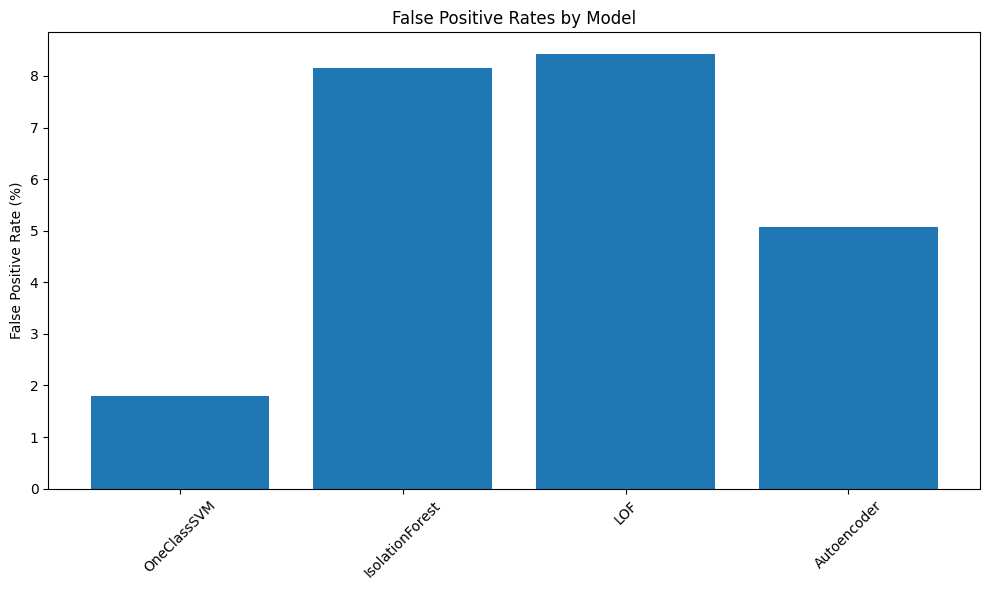

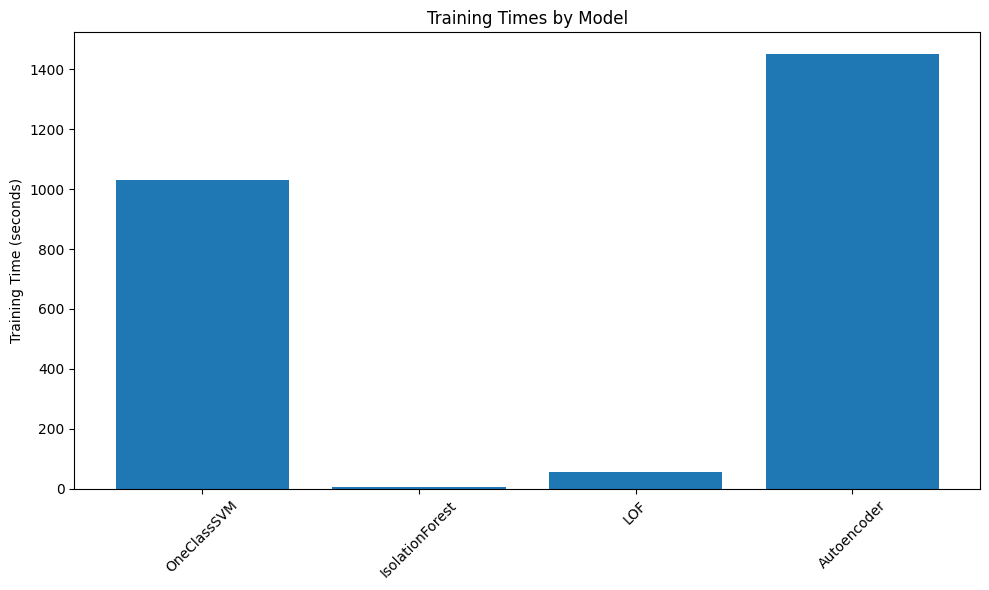

In [ ]:
# Create comparison plots
import matplotlib.pyplot as plt

# Plot false positive rates
models = list(results.keys())
fp_rates = [results[model]['false_positive_rate_%'] for model in models]

plt.figure(figsize=(10, 6))
plt.bar(models, fp_rates)
plt.title('False Positive Rates by Model')
plt.ylabel('False Positive Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot training times
training_times = [anomaly_models.training_times[model] for model in models]
plt.figure(figsize=(10, 6))
plt.bar(models, training_times)
plt.title('Training Times by Model')
plt.ylabel('Training Time (seconds)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Add this code to your current notebook after training models

import pickle
import joblib
import os
import json
from datetime import datetime

# Create directory to save models
save_path = "saved_anomaly_models"
os.makedirs(save_path, exist_ok=True)

# Save sklearn models
joblib.dump(anomaly_models.models['OneClassSVM'], f"{save_path}/ocsvm_model.pkl")
joblib.dump(anomaly_models.models['IsolationForest'], f"{save_path}/isolation_forest_model.pkl")
joblib.dump(anomaly_models.models['LOF'], f"{save_path}/lof_model.pkl")

# Save autoencoder
anomaly_models.models['Autoencoder'].save(f"{save_path}/autoencoder_model.keras")

# Save scalers/preprocessors if any
if hasattr(anomaly_models, 'scalers') and anomaly_models.scalers:
    joblib.dump(anomaly_models.scalers, f"{save_path}/scalers.pkl")

# Save autoencoder threshold
autoencoder_info = {
    'threshold': anomaly_models.model_info.get('Autoencoder', {}).get('threshold', None)
}
with open(f"{save_path}/autoencoder_info.json", 'w') as f:
    json.dump(autoencoder_info, f)

print("✅ Models saved successfully!")
print(f"📁 Location: {save_path}")
print("Files saved:")
print("- ocsvm_model.pkl")
print("- isolation_forest_model.pkl")
print("- lof_model.pkl")
print("- autoencoder_model.keras")
print("- autoencoder_info.json")
if hasattr(anomaly_models, 'scalers') and anomaly_models.scalers:
    print("- scalers.pkl")

✅ Models saved successfully!
📁 Location: saved_anomaly_models
Files saved:
- ocsvm_model.pkl
- isolation_forest_model.pkl
- lof_model.pkl
- autoencoder_model.keras
- autoencoder_info.json
- scalers.pkl
